# IEEE-CIS fraud detection: saved-model evaluation

**This notebook contains no model training.** Run from top to bottom after restarting Python. It loads `models/selected_catboost.cbm` and its metadata, reconstructs the original chronological holdout, and recreates metrics, figures, and error analysis.

Required: the original training CSVs, saved model and metadata, and `results/validation_experiments.csv`. The project path is set in the first code cell; adjust it if moving this project. Reading the transaction data requires memory and takes time, but models are not refitted.

Existing displayed outputs were preserved from the original notebook. Execution counts were cleared during organization; this organized copy has not been executed end to end.

The threshold remains fixed at its validation-selected value. Holdout findings are descriptive and must not be used to retune this model.

## Load saved model and configuration

In [ ]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display
from catboost import CatBoostClassifier

PROJECT_DIR = Path(
    "C:/Users/caleb/OneDrive/Documents/UARK Classes/"
    "Fall2026/Data_Mining/ieee-fraud-project"
)
DATA_DIR = PROJECT_DIR / "data"
MODEL_DIR = PROJECT_DIR / "models"
RESULTS_DIR = PROJECT_DIR / "results"
RESULTS_DIR.mkdir(exist_ok=True)

with open(MODEL_DIR / "selected_model_metadata.json") as file:
    metadata = json.load(file)

final_model = CatBoostClassifier()
final_model.load_model(str(MODEL_DIR / "selected_catboost.cbm"))

final_threshold = metadata["threshold"]
combined_features = metadata["features"]
combined_cat_features = metadata["categorical_features"]

print("Loaded:", metadata["model_name"])
print("Trees:", final_model.tree_count_)
print(f"Threshold: {final_threshold:.6f}")

Loaded: CatBoost — transaction + identity, 2000 budget
Trees: 1999
Threshold: 0.173891


## Reconstruct the original holdout

In [ ]:
transactions = pd.read_csv(DATA_DIR / "train_transaction.csv")

ordered = transactions.sort_values(
    "TransactionDT"
).reset_index(drop=True)

holdout_start = ordered.iloc[
    int(len(ordered) * 0.85)
]["TransactionDT"]

holdout_df = ordered.loc[
    ordered["TransactionDT"] >= holdout_start
].copy()

del transactions, ordered

identity = pd.read_csv(DATA_DIR / "train_identity.csv")

holdout_df = holdout_df.merge(
    identity,
    on="TransactionID",
    how="left",
    validate="one_to_one"
)

del identity

assert len(holdout_df) == 88581
assert holdout_df["isFraud"].sum() == 3083

print("Holdout restored:", holdout_df.shape)

Holdout restored: (88581, 434)


## Prepare features and generate predictions

In [ ]:
def prepare_catboost_inputs(frame, feature_names, category_names):
    prepared = frame[feature_names].copy()

    for column in category_names:
        prepared[column] = (
            prepared[column]
            .astype("string")
            .fillna("Missing")
            .astype(str)
        )

    return prepared


X_holdout_combined = prepare_catboost_inputs(
    holdout_df,
    combined_features,
    combined_cat_features
)

assert list(X_holdout_combined.columns) == list(final_model.feature_names_)
y_holdout = holdout_df["isFraud"]

final_holdout_prob = final_model.predict_proba(
    X_holdout_combined
)[:, 1]

print(f"Generated {len(final_holdout_prob):,} holdout predictions.")

Generated 88,581 holdout predictions.


## Evaluate the frozen threshold and save predictions

In [ ]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

# Apply the threshold saved during validation—do not tune it here.
final_holdout_pred = (
    final_holdout_prob >= final_threshold
).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_holdout,
    final_holdout_pred,
    labels=[0, 1]
).ravel()

holdout_results = pd.DataFrame([{
    "model": metadata["model_name"],
    "threshold": final_threshold,
    "roc_auc": roc_auc_score(y_holdout, final_holdout_prob),
    "average_precision": average_precision_score(
        y_holdout, final_holdout_prob
    ),
    "precision": precision_score(
        y_holdout, final_holdout_pred, zero_division=0
    ),
    "recall": recall_score(
        y_holdout, final_holdout_pred, zero_division=0
    ),
    "f1": f1_score(
        y_holdout, final_holdout_pred, zero_division=0
    ),
    "fraud_caught": int(tp),
    "fraud_missed": int(fn),
    "false_alarms": int(fp),
    "legitimate_cleared": int(tn),
}])

display(holdout_results.round(4))

holdout_results.to_csv(
    RESULTS_DIR / "holdout_results.csv",
    index=False
)

# Save predictions for later plots and error analysis.
holdout_predictions = holdout_df[
    [
        "TransactionID", "TransactionDT",
        "ProductCD", "TransactionAmt", "isFraud"
    ]
].copy()

holdout_predictions["catboost_probability"] = final_holdout_prob
holdout_predictions["catboost_prediction"] = final_holdout_pred

holdout_predictions.to_csv(
    RESULTS_DIR / "holdout_predictions.csv",
    index=False
)

print("Holdout results and predictions saved.")

,model,threshold,roc_auc,average_precision,precision,recall,f1,fraud_caught,fraud_missed,false_alarms,legitimate_cleared
0,"CatBoost — transaction + identity, 2000 budget",0.1739,0.9096,0.5621,0.5683,0.5196,0.5429,1602,1481,1217,84281


Holdout results and predictions saved.


## Save evaluation figures

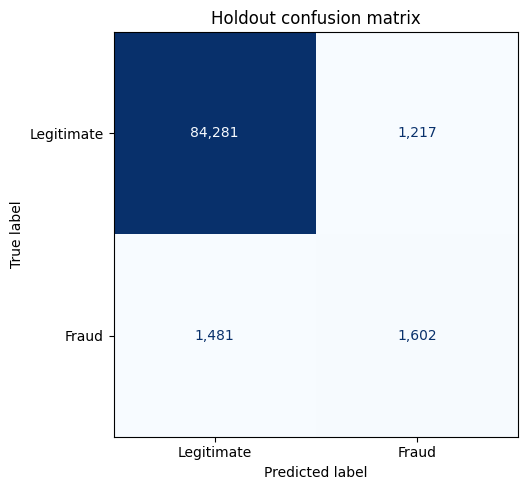

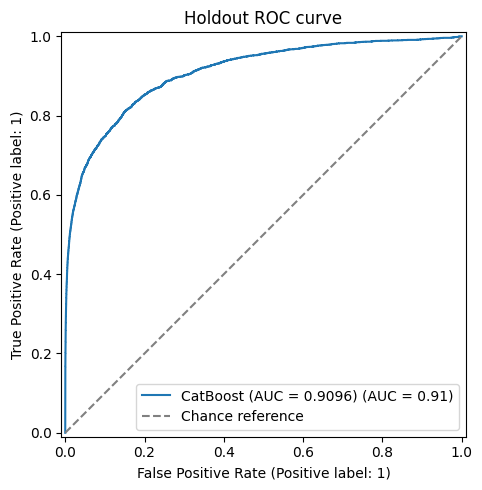

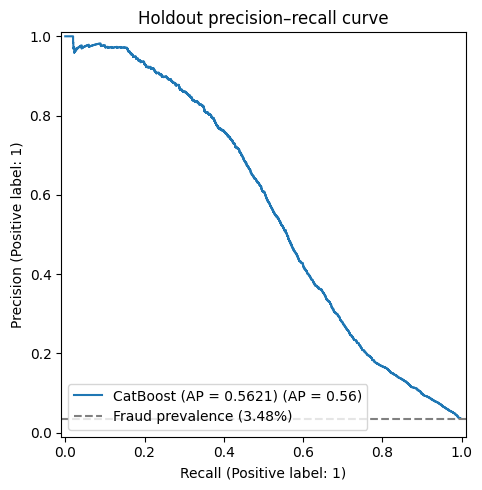

Figures saved to: C:\Users\caleb\OneDrive\Documents\UARK Classes\Fall2026\Data_Mining\ieee-fraud-project\results\figures


In [ ]:
import matplotlib.pyplot as plt

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay,
    roc_auc_score,
    average_precision_score,
)

RESULTS_DIR = PROJECT_DIR / "results"
FIGURE_DIR = RESULTS_DIR / "figures"
FIGURE_DIR.mkdir(exist_ok=True)

saved_predictions = pd.read_csv(
    RESULTS_DIR / "holdout_predictions.csv"
)

actual = saved_predictions["isFraud"]
probabilities = saved_predictions["catboost_probability"]
predictions = saved_predictions["catboost_prediction"]

# 1. Confusion matrix at the frozen validation threshold.
fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    actual,
    predictions,
    labels=[0, 1],
    display_labels=["Legitimate", "Fraud"],
    values_format=",d",
    cmap="Blues",
    colorbar=False,
    ax=ax,
)

ax.set_title("Holdout confusion matrix")
fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "holdout_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 2. ROC curve.
auc = roc_auc_score(actual, probabilities)
fig, ax = plt.subplots(figsize=(6, 5))

RocCurveDisplay.from_predictions(
    actual,
    probabilities,
    name=f"CatBoost (AUC = {auc:.4f})",
    ax=ax,
)

ax.plot([0, 1], [0, 1], "--", color="gray", label="Chance reference")
ax.set_title("Holdout ROC curve")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "holdout_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 3. Precision–recall curve.
ap = average_precision_score(actual, probabilities)
fig, ax = plt.subplots(figsize=(6, 5))

PrecisionRecallDisplay.from_predictions(
    actual,
    probabilities,
    name=f"CatBoost (AP = {ap:.4f})",
    ax=ax,
)

ax.axhline(
    actual.mean(),
    linestyle="--",
    color="gray",
    label=f"Fraud prevalence ({actual.mean():.2%})",
)

ax.set_title("Holdout precision–recall curve")
ax.legend(loc="best")
fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "holdout_precision_recall_curve.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Figures saved to:", FIGURE_DIR)

## Calculate feature importance explicitly

,feature,importance
0,card1,10.322
1,addr1,4.876
2,C13,4.137
3,M5,3.490
4,TransactionAmt,3.469
5,P_emaildomain,3.349
6,TransactionDT,3.229
7,C1,3.053
8,C14,2.917
9,DeviceInfo,2.261


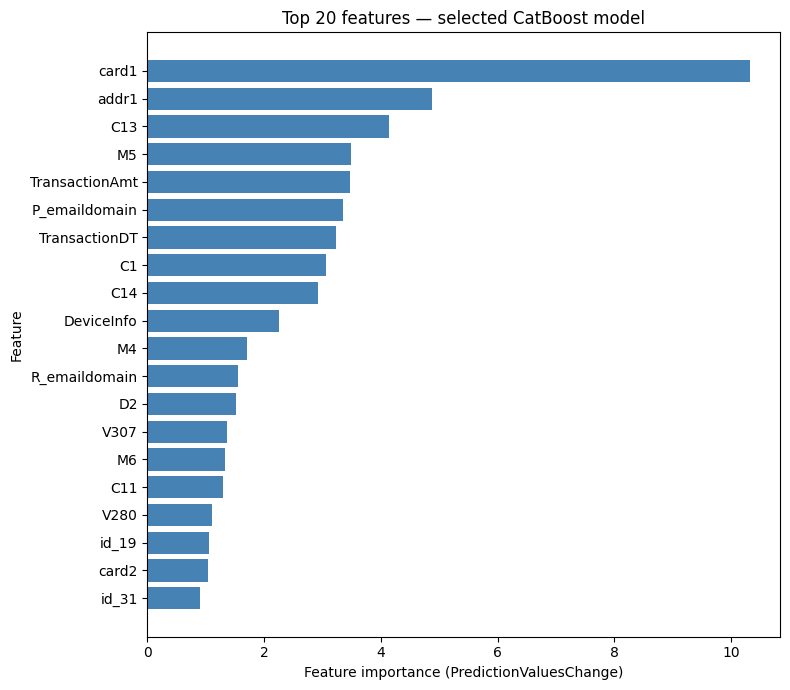

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Explicitly calculate importance from the fitted model.
importance_values = final_model.get_feature_importance(
    type="PredictionValuesChange",
    thread_count=4
)

importance_values = np.asarray(importance_values, dtype=float)

# Stop rather than save an empty or invalid chart.
assert len(importance_values) == len(final_model.feature_names_)
assert np.isfinite(importance_values).all(), "Invalid importance values."
assert importance_values.sum() > 0, "All importance values are zero."

feature_importance = pd.DataFrame({
    "feature": final_model.feature_names_,
    "importance": importance_values
}).sort_values("importance", ascending=False).reset_index(drop=True)

display(feature_importance.head(20).round(3))

# Replace the earlier CSV containing None values.
feature_importance.to_csv(
    RESULTS_DIR / "feature_importance.csv",
    index=False
)

top_features = feature_importance.head(20).iloc[::-1]
positions = np.arange(len(top_features))

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(
    positions,
    top_features["importance"].to_numpy(),
    color="steelblue"
)
ax.set_yticks(positions)
ax.set_yticklabels(top_features["feature"].astype(str))

ax.set_title("Top 20 features — selected CatBoost model")
ax.set_xlabel("Feature importance (PredictionValuesChange)")
ax.set_ylabel("Feature")
fig.tight_layout()

FIGURE_DIR = RESULTS_DIR / "figures"
FIGURE_DIR.mkdir(exist_ok=True)

# Replace the earlier blank chart.
fig.savefig(
    FIGURE_DIR / "feature_importance_top20.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## Describe errors by product category

In [ ]:
# Load the saved predictions so this analysis can be rerun independently.
error_data = pd.read_csv(
    RESULTS_DIR / "holdout_predictions.csv"
)

actual = error_data["isFraud"]
predicted = error_data["catboost_prediction"]

error_data["fraud_caught"] = (
    (actual == 1) & (predicted == 1)
).astype(int)

error_data["fraud_missed"] = (
    (actual == 1) & (predicted == 0)
).astype(int)

error_data["false_alarms"] = (
    (actual == 0) & (predicted == 1)
).astype(int)

error_data["legitimate_count"] = (actual == 0).astype(int)

category_errors = error_data.groupby(
    "ProductCD", dropna=False
).agg(
    transactions=("isFraud", "size"),
    fraud_count=("isFraud", "sum"),
    legitimate_count=("legitimate_count", "sum"),
    fraud_caught=("fraud_caught", "sum"),
    fraud_missed=("fraud_missed", "sum"),
    false_alarms=("false_alarms", "sum"),
)

# Replace zero denominators with NaN: the rate is undefined in that case.
category_errors["recall_percent"] = (
    category_errors["fraud_caught"]
    / category_errors["fraud_count"].replace(0, np.nan)
    * 100
)

category_errors["precision_percent"] = (
    category_errors["fraud_caught"]
    / (
        category_errors["fraud_caught"]
        + category_errors["false_alarms"]
    ).replace(0, np.nan)
    * 100
)

category_errors["false_positive_rate_percent"] = (
    category_errors["false_alarms"]
    / category_errors["legitimate_count"].replace(0, np.nan)
    * 100
)

display(category_errors.round(2))

category_errors.to_csv(
    RESULTS_DIR / "holdout_errors_by_product.csv"
)

,transactions,fraud_count,legitimate_count,fraud_caught,fraud_missed,false_alarms,recall_percent,precision_percent,false_positive_rate_percent
ProductCD,,,,,,,,,
C,9388,1270,8118,944,326,478,74.33,66.39,5.89
H,2562,164,2398,92,72,104,56.10,46.94,4.34
R,4190,212,3978,173,39,120,81.60,59.04,3.02
S,2973,144,2829,70,74,24,48.61,74.47,0.85
W,69468,1293,68175,323,970,491,24.98,39.68,0.72


## Export comparison table and environment versions

In [ ]:
from pathlib import Path
import json
import platform
import importlib.metadata
import pandas as pd

PROJECT_DIR = Path(
    "C:/Users/caleb/OneDrive/Documents/UARK Classes/"
    "Fall2026/Data_Mining/ieee-fraud-project"
)
RESULTS_DIR = PROJECT_DIR / "results"
MODEL_DIR = PROJECT_DIR / "models"

# Load previously saved results—no training or prediction needed.
validation_results = pd.read_csv(
    RESULTS_DIR / "validation_experiments.csv"
)
holdout_results = pd.read_csv(
    RESULTS_DIR / "holdout_results.csv"
)

validation_results["evaluation_set"] = "Validation (model/threshold selection)"
holdout_results["evaluation_set"] = "Holdout (final evaluation)"

report_columns = [
    "evaluation_set",
    "model",
    "threshold",
    "roc_auc",
    "average_precision",
    "precision",
    "recall",
    "f1",
]

report_results = pd.concat(
    [
        validation_results[report_columns],
        holdout_results[report_columns],
    ],
    ignore_index=True
)

report_results.to_csv(
    RESULTS_DIR / "report_model_comparison.csv",
    index=False
)

display(report_results.round(4))

# Record the currently installed software versions.
packages = [
    "pandas",
    "numpy",
    "scikit-learn",
    "catboost",
    "matplotlib",
]

environment = {
    "python": platform.python_version(),
    "packages": {
        package: importlib.metadata.version(package)
        for package in packages
    },
}

with open(RESULTS_DIR / "environment_versions.json", "w") as file:
    json.dump(environment, file, indent=2)

print("Report comparison table and environment versions saved.")

,evaluation_set,model,threshold,roc_auc,average_precision,precision,recall,f1
0,Validation (model/threshold selection),Logistic regression — selected features,0.1221,0.7972,0.1685,0.2302,0.2870,0.2554
1,Validation (model/threshold selection),CatBoost — selected features,0.1421,0.8239,0.2185,0.2895,0.3087,0.2988
2,Validation (model/threshold selection),CatBoost — all transaction features,0.2305,0.9270,0.6248,0.6873,0.5391,0.6043
3,Validation (model/threshold selection),CatBoost — transaction + identity,0.2057,0.9300,0.6363,0.6836,0.5496,0.6093
4,Validation (model/threshold selection),CatBoost — combined + engineered features,0.2225,0.9289,0.6351,0.6950,0.5348,0.6045
5,Validation (model/threshold selection),"CatBoost — transaction + identity, 2000 budget",0.1739,0.9334,0.6505,0.6786,0.5684,0.6186
6,Holdout (final evaluation),"CatBoost — transaction + identity, 2000 budget",0.1739,0.9096,0.5621,0.5683,0.5196,0.5429


Report comparison table and environment versions saved.


## Interpretation

The frozen model achieved holdout ROC-AUC 0.9096, average precision 0.5621, precision 0.5683, recall 0.5196, and F1 0.5429. It detected 1,602 fraud cases, missed 1,481, and produced 1,217 false alarms.

Category W contained 970 missed fraud cases. Importance ranked card1, addr1, and C13 highest; this does not establish causation or the direction of effects. Performance declined from validation to holdout; temporal changes and validation selection are possible explanations, not established causes.

Final holdout evaluation is for the saved model trained on the first 70% of labeled transactions. No full-data refit or Kaggle submission is needed for this project.